# Etapa 5 — Redes Bayesianas nas escolas do Amazonas
Censo Escolar 2025. Modelamos as dependências entre seis variáveis do CSV da Etapa 1 com uma rede Bayesiana e usamos a rede para responder consultas por inferência.

As variáveis são **LOC** (`TP_LOCALIZACAO`: 1 urbana, 2 rural), **DEP** (`TP_DEPENDENCIA`: 1 federal, 2 estadual, 3 municipal, 4 privada), **GER** (`IN_ENERGIA_GERADOR_FOSSIL`), **BIB** (`IN_BIBLIOTECA`), **LAB** (`IN_LABORATORIO_INFORMATICA`) e **Y** (`infra_digital_basica`). Na Etapa 1, Y vale 1 quando a escola informa internet para alunos e ao menos um tipo de aparelho para eles (desktop, portátil ou tablet). As colunas que definem Y não entram na rede, então Y **não** é uma função determinística das outras cinco variáveis.

Tarefas desta etapa:
1. Desenhar o DAG com 4–6 nós, justificando cada aresta.
2. Estimar as CPTs a partir dos dados.
3. Implementar a inferência por enumeração do zero.
4. Comparar com o `VariableElimination` do pgmpy.
5. Aplicar d-separação para verificar 2 independências condicionais.
6. Calcular quantos parâmetros a rede economiza em relação à conjunta.

In [1]:
import itertools
from math import prod

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import FancyArrowPatch
from scipy.stats import chi2

NOS = ["TP_LOCALIZACAO", "TP_DEPENDENCIA", "IN_ENERGIA_GERADOR_FOSSIL",
       "IN_BIBLIOTECA", "IN_LABORATORIO_INFORMATICA", "infra_digital_basica"]
ALIAS = {"TP_LOCALIZACAO": "LOC", "TP_DEPENDENCIA": "DEP", "IN_ENERGIA_GERADOR_FOSSIL": "GER",
         "IN_BIBLIOTECA": "BIB", "IN_LABORATORIO_INFORMATICA": "LAB", "infra_digital_basica": "Y"}
POR_ALIAS = {a: n for n, a in ALIAS.items()}

dados = pd.read_csv("dados_etapa1.csv")
assert dados["CO_ENTIDADE"].is_unique
assert not dados[NOS].isna().any().any()
assert (dados[NOS] % 1 == 0).all().all()          # todos os valores são inteiros (1.0 -> 1)
df = dados[NOS].astype(int)                       # CO_ENTIDADE é só identificador: fora da rede
N = len(df)
print(f"Escolas analisadas: {N}")
for no in NOS:
    print(f"{ALIAS[no]:>3} ({no}): {df[no].value_counts().sort_index().to_dict()}")

Escolas analisadas: 5562
LOC (TP_LOCALIZACAO): {1: 1896, 2: 3666}
DEP (TP_DEPENDENCIA): {1: 19, 2: 758, 3: 4381, 4: 404}
GER (IN_ENERGIA_GERADOR_FOSSIL): {0: 4868, 1: 694}
BIB (IN_BIBLIOTECA): {0: 4207, 1: 1355}
LAB (IN_LABORATORIO_INFORMATICA): {0: 4607, 1: 955}
  Y (infra_digital_basica): {0: 4555, 1: 1007}


## 1. O DAG e a justificativa das arestas
A rede tem 6 nós e 8 arestas. LOC e DEP descrevem o contexto da escola, GER, LAB e BIB descrevem sua infraestrutura, e Y é o alvo. Cada aresta é uma dependência plausível do domínio, não uma relação causal comprovada.

| # | Aresta | Justificativa |
|---|--------|---------------|
| 1 | LOC → DEP | Escolas rurais são majoritariamente municipais, e a rede privada se concentra em áreas urbanas. |
| 2 | LOC → GER | Em áreas rurais e ribeirinhas do AM a rede elétrica é limitada, e muitas escolas dependem de gerador a combustível fóssil. |
| 3 | DEP → LAB | A rede (federal, estadual, municipal ou privada) define orçamento e política de investimento em laboratórios. |
| 4 | DEP → BIB | O investimento em infraestrutura física varia por rede. |
| 5 | GER → LAB | Equipamentos de informática exigem energia confiável. Depender de gerador dificulta instalar e manter um laboratório. |
| 6 | GER → Y | Internet para alunos requer energia estável. O efeito é direto, além do que passa pelo laboratório (5 seguida de 7). |
| 7 | LAB → Y | Escolas com laboratório tendem a ter desktops e conexão disponíveis aos alunos. A associação é forte, mas não definicional. |
| 8 | BIB → Y | Proxy de investimento geral em infraestrutura escolar. É a aresta mais fraca e pode ser testada com qui-quadrado ou informação mútua. |

Deixamos de fora `DEP → Y` e `LOC → Y` para manter a CPT do alvo pequena (8 configurações de pais). A Seção 3 mostra o custo dessa escolha.

6 nós e 8 arestas; o grafo é acíclico.


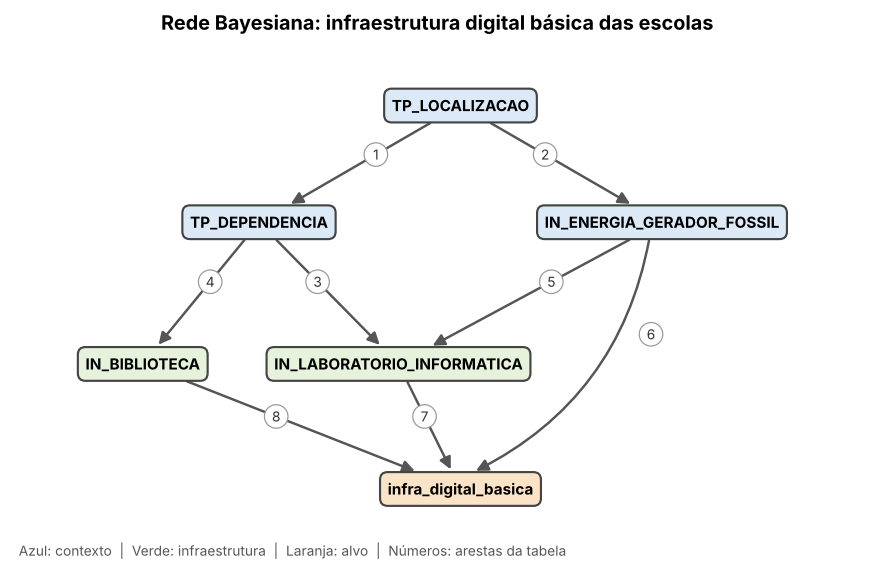

In [2]:
ESTRUTURA = {                                    # nó -> pais (a ordem das chaves é topológica)
    "TP_LOCALIZACAO": [],
    "TP_DEPENDENCIA": ["TP_LOCALIZACAO"],
    "IN_ENERGIA_GERADOR_FOSSIL": ["TP_LOCALIZACAO"],
    "IN_BIBLIOTECA": ["TP_DEPENDENCIA"],
    "IN_LABORATORIO_INFORMATICA": ["TP_DEPENDENCIA", "IN_ENERGIA_GERADOR_FOSSIL"],
    "infra_digital_basica": ["IN_ENERGIA_GERADOR_FOSSIL", "IN_LABORATORIO_INFORMATICA", "IN_BIBLIOTECA"],
}
ARESTAS = [  # a numeração é a da tabela de justificativas
    ("TP_LOCALIZACAO", "TP_DEPENDENCIA"), ("TP_LOCALIZACAO", "IN_ENERGIA_GERADOR_FOSSIL"),
    ("TP_DEPENDENCIA", "IN_LABORATORIO_INFORMATICA"), ("TP_DEPENDENCIA", "IN_BIBLIOTECA"),
    ("IN_ENERGIA_GERADOR_FOSSIL", "IN_LABORATORIO_INFORMATICA"), ("IN_ENERGIA_GERADOR_FOSSIL", "infra_digital_basica"),
    ("IN_LABORATORIO_INFORMATICA", "infra_digital_basica"), ("IN_BIBLIOTECA", "infra_digital_basica"),
]
assert sorted(ARESTAS) == sorted((p, f) for f, ps in ESTRUTURA.items() for p in ps)

vistos = set()                                   # acíclico: todo pai aparece antes do filho
for no, pais in ESTRUTURA.items():
    assert all(p in vistos for p in pais), no
    vistos.add(no)
print(f"{len(ESTRUTURA)} nós e {len(ARESTAS)} arestas; o grafo é acíclico.")

POS = {"TP_LOCALIZACAO": (5.0, 4.6), "TP_DEPENDENCIA": (2.4, 3.2), "IN_ENERGIA_GERADOR_FOSSIL": (7.6, 3.2),
       "IN_BIBLIOTECA": (0.9, 1.5), "IN_LABORATORIO_INFORMATICA": (4.2, 1.5), "infra_digital_basica": (5.0, 0.0)}
COR = {"TP_LOCALIZACAO": "#DCE9F7", "TP_DEPENDENCIA": "#DCE9F7", "IN_ENERGIA_GERADOR_FOSSIL": "#DCE9F7",
       "IN_BIBLIOTECA": "#E6F2DC", "IN_LABORATORIO_INFORMATICA": "#E6F2DC", "infra_digital_basica": "#FBE3C8"}
CURVA = {("IN_ENERGIA_GERADOR_FOSSIL", "infra_digital_basica"): -0.25}   # contorna o nó LAB

fig, ax = plt.subplots(figsize=(10, 6.2))
ax.set_xlim(-0.8, 10.2); ax.set_ylim(-0.9, 5.4); ax.axis("off")
caixas = {no: ax.text(x, y, no, ha="center", va="center", fontsize=10, fontweight="bold", zorder=3,
                      bbox=dict(boxstyle="round,pad=0.5", fc=COR[no], ec="#444444", lw=1.4))
          for no, (x, y) in POS.items()}
fig.canvas.draw()                                # fixa o tamanho das caixas antes de ligar as setas
inv = ax.transData.inverted()
meia = {}                                        # meia largura e meia altura de cada caixa, em unidades do gráfico
for no, t in caixas.items():
    bb = t.get_bbox_patch().get_window_extent()
    (bx0, by0), (bx1, by1) = inv.transform([[bb.x0, bb.y0], [bb.x1, bb.y1]])
    meia[no] = ((bx1 - bx0) / 2, (by1 - by0) / 2)

def borda(no, alvo):                             # ponto onde a reta centro->alvo cruza a borda da caixa
    (cx, cy), (tx, ty) = POS[no], POS[alvo]
    dx, dy = tx - cx, ty - cy
    k = min(meia[no][0] / abs(dx) if dx else np.inf, meia[no][1] / abs(dy) if dy else np.inf)
    return cx + dx * k, cy + dy * k

for i, (pai, filho) in enumerate(ARESTAS, 1):
    rad = CURVA.get((pai, filho), 0.0)
    ax.add_patch(FancyArrowPatch(borda(pai, filho), borda(filho, pai), arrowstyle="-|>", mutation_scale=16,
                                 lw=1.6, color="#555555", connectionstyle=f"arc3,rad={rad}", zorder=1,
                                 shrinkA=1, shrinkB=2))
    (x0, y0), (x1, y1) = POS[pai], POS[filho]
    mx, my = x0 + 0.42 * (x1 - x0), y0 + 0.42 * (y1 - y0)
    if rad:
        mx += 0.95
    ax.text(mx, my, str(i), ha="center", va="center", fontsize=9, color="#333333", zorder=4,
            bbox=dict(boxstyle="circle,pad=0.25", fc="white", ec="#999999", lw=0.8))
ax.set_title("Rede Bayesiana: infraestrutura digital básica das escolas", fontsize=13, fontweight="bold")
ax.text(-0.7, -0.8, "Azul: contexto  |  Verde: infraestrutura  |  Laranja: alvo  |  Números: arestas da tabela",
        fontsize=9, color="#555555")
plt.show()

## 2. Estimação das CPTs
Cada nó recebe uma tabela de probabilidade condicional dada a configuração dos seus pais. Estimamos por contagem com **suavização de Laplace** (α = 1):

$$P(X = x \mid \text{pais} = c) = \frac{N(x, c) + \alpha}{N(c) + \alpha \cdot |X|}$$

O termo α evita probabilidade zero em combinações raras. Na tabela, `N` é o número de escolas em cada configuração de pais, e serve para avaliar a confiança de cada linha.

In [3]:
ALPHA = 1.0
dominios = {no: sorted(df[no].unique().tolist()) for no in NOS}

def aprender_cpts(df, estrutura, dominios, alpha=ALPHA):
    cpts, n_pais = {}, {}
    for v, pais in estrutura.items():
        configs = list(itertools.product(*[dominios[p] for p in pais]))
        contagem = {cfg: {x: 0 for x in dominios[v]} for cfg in configs}
        for linha in df[pais + [v]].itertuples(index=False, name=None):
            contagem[tuple(linha[:-1])][linha[-1]] += 1
        cpts[v], n_pais[v] = {}, {}
        for cfg, c in contagem.items():
            n = sum(c.values())
            n_pais[v][cfg] = n
            cpts[v][cfg] = {x: (k + alpha) / (n + alpha * len(dominios[v])) for x, k in c.items()}
    return cpts, n_pais

cpts, n_pais = aprender_cpts(df, ESTRUTURA, dominios)
for v in NOS:                                    # toda coluna de CPT soma 1
    for cfg in cpts[v]:
        assert abs(sum(cpts[v][cfg].values()) - 1) < 1e-12

def tabela_cpt(v):
    pais = ESTRUTURA[v]
    linhas = {}
    for cfg, probs in cpts[v].items():
        rotulo = ", ".join(f"{ALIAS[p]}={c}" for p, c in zip(pais, cfg)) or "(sem pais)"
        linhas[rotulo] = {**{f"P({ALIAS[v]}={x})": p for x, p in probs.items()}, "N": n_pais[v][cfg]}
    return pd.DataFrame.from_dict(linhas, orient="index")

for i, v in enumerate(NOS, 1):
    pais = ", ".join(ALIAS[p] for p in ESTRUTURA[v]) or "—"
    print(f"CPT {i}: P({ALIAS[v]} | {pais})")
    print(tabela_cpt(v).round(4).to_string())
    pequenas = [cfg for cfg, n in n_pais[v].items() if n < 30 and ESTRUTURA[v]]
    if pequenas:
        print(f"  Atenção: {len(pequenas)} configuração(ões) de pais com N < 30: {pequenas}")
    print()

CPT 1: P(LOC | —)
            P(LOC=1)  P(LOC=2)     N
(sem pais)    0.3409    0.6591  5562

CPT 2: P(DEP | LOC)
       P(DEP=1)  P(DEP=2)  P(DEP=3)  P(DEP=4)     N
LOC=1    0.0089    0.3095    0.4705    0.2111  1896
LOC=2    0.0011    0.0469    0.9507    0.0014  3666

CPT 3: P(GER | LOC)
       P(GER=0)  P(GER=1)     N
LOC=1    0.9884    0.0116  1896
LOC=2    0.8162    0.1838  3666

CPT 4: P(BIB | DEP)
       P(BIB=0)  P(BIB=1)     N
DEP=1    0.1429    0.8571    19
DEP=2    0.3039    0.6961   758
DEP=3    0.8715    0.1285  4381
DEP=4    0.3867    0.6133   404
  Atenção: 1 configuração(ões) de pais com N < 30: [(1,)]

CPT 5: P(LAB | DEP, GER)
              P(LAB=0)  P(LAB=1)     N
DEP=1, GER=0    0.1250    0.8750    14
DEP=1, GER=1    0.2857    0.7143     5
DEP=2, GER=0    0.4588    0.5412   739
DEP=2, GER=1    0.9048    0.0952    19
DEP=3, GER=0    0.8925    0.1075  3727
DEP=3, GER=1    0.9787    0.0213   654
DEP=4, GER=0    0.7000    0.3000   388
DEP=4, GER=1    0.5000    0.5000    1

**O que as CPTs dizem sobre as arestas.**
- **Bem sustentadas:** LOC → DEP (95% das escolas rurais são municipais, contra 47% das urbanas), LOC → GER (18,4% das rurais usam gerador, contra 1,2% das urbanas), DEP → BIB (só 12,9% das municipais têm biblioteca, contra 61% a 86% nas demais redes) e LAB → Y (ter laboratório eleva P(Y = 1) de cerca de 7% para cerca de 66%).
- **GER → LAB:** nas redes estadual e municipal, o gerador reduz muito a chance de laboratório (54% para 9,5% e 10,8% para 2,1%).
- **BIB → Y é a mais fraca:** com laboratório, a biblioteca quase não muda P(Y = 1) (0,662 contra 0,664). Ela só pesa sem laboratório (0,070 para 0,178).
- **GER → Y é incerta:** o efeito direto muda de sinal entre as configurações, e as com gerador = 1 têm poucas escolas.

**Cuidado com as amostras pequenas.** DEP = 1 (federal) tem só 19 escolas. Nas linhas com N = 8 e N = 18 da CPT do alvo, a suavização puxa o valor para 0,5 (a proporção bruta é 0,75 e 0,83, contra 0,70 e 0,80 suavizados). Ao citar essas linhas no relatório, informe o N.

## 3. Inferência por enumeração
Para responder $P(X \mid e)$, somamos a conjunta sobre todas as variáveis ocultas e normalizamos. A conjunta é o produto das CPTs:

$$P(x_1, \dots, x_n) = \prod_i P(x_i \mid \text{pais}(x_i))$$

O algoritmo é o ENUMERATION-ASK. A função `enumerar_todas` percorre as variáveis em ordem topológica: se a variável está na evidência, multiplica pelo seu fator, e se não está, soma sobre todos os seus valores.

Para validar, comparamos o resultado com um segundo método que não usa recursão: marginalizar a conjunta completa de 128 combinações.

In [4]:
def p_cond(v, valor, atrib):
    cfg = tuple(atrib[p] for p in ESTRUTURA[v])
    return cpts[v][cfg][valor]

def enumerar_todas(variaveis, evidencia):
    if not variaveis:
        return 1.0
    y, resto = variaveis[0], variaveis[1:]
    if y in evidencia:
        return p_cond(y, evidencia[y], evidencia) * enumerar_todas(resto, evidencia)
    total = 0.0
    for valor in dominios[y]:
        estendida = {**evidencia, y: valor}
        total += p_cond(y, valor, estendida) * enumerar_todas(resto, estendida)
    return total

def consulta(X, evidencia=None):
    evidencia = dict(evidencia or {})
    assert X in ESTRUTURA and X not in evidencia
    for var, val in evidencia.items():
        assert var in ESTRUTURA and val in dominios[var], (var, val)
    Q = {x: enumerar_todas(list(ESTRUTURA), {**evidencia, X: x}) for x in dominios[X]}
    z = sum(Q.values())
    assert z > 0, "evidência com probabilidade zero no modelo"
    return {x: q / z for x, q in Q.items()}

# Validação: marginalização da conjunta completa (algoritmo independente)
def prob_conjunta(atrib):
    return prod(p_cond(v, atrib[v], atrib) for v in ESTRUTURA)

def consulta_por_conjunta(X, evidencia=None):
    evidencia = evidencia or {}
    soma = {x: 0.0 for x in dominios[X]}
    for valores in itertools.product(*[dominios[v] for v in ESTRUTURA]):
        a = dict(zip(ESTRUTURA, valores))
        if all(a[k] == v for k, v in evidencia.items()):
            soma[a[X]] += prob_conjunta(a)
    z = sum(soma.values())
    return {x: s / z for x, s in soma.items()}

total_conjunta = sum(prob_conjunta(dict(zip(ESTRUTURA, vals)))
                     for vals in itertools.product(*[dominios[v] for v in ESTRUTURA]))
assert abs(total_conjunta - 1) < 1e-9
maior, n_consultas = 0.0, 0
for X in NOS:
    evidencias = [{}] + [{Z: z} for Z in NOS if Z != X for z in dominios[Z]]
    for ev in evidencias:
        a, b = consulta(X, ev), consulta_por_conjunta(X, ev)
        maior = max(maior, max(abs(a[x] - b[x]) for x in a))
        n_consultas += 1
assert maior < 1e-12
print(f"Autoteste: a conjunta soma {total_conjunta:.12f}; {n_consultas} consultas conferidas contra a "
      f"marginalização da conjunta (maior diferença {maior:.1e}).")

Autoteste: a conjunta soma 1.000000000000; 76 consultas conferidas contra a marginalização da conjunta (maior diferença 2.2e-16).


In [5]:
def freq_empirica(X, evidencia):
    sub = df
    for var, val in evidencia.items():
        sub = sub[sub[var] == val]
    return sub[X].value_counts(normalize=True).to_dict(), len(sub)

def converter(ev):                               # {"LOC": 2} -> {"TP_LOCALIZACAO": 2}
    return {POR_ALIAS[k]: v for k, v in ev.items()}

EXEMPLOS = [  # (variável, valor, evidência), em aliases
    ("Y", 1, {}),
    ("Y", 1, {"LOC": 2}),
    ("Y", 1, {"LOC": 2, "DEP": 3}),
    ("Y", 1, {"LAB": 1}),
    ("Y", 1, {"DEP": 3, "GER": 1}),
    ("LOC", 2, {"Y": 1}),
    ("GER", 1, {"Y": 1}),
    ("DEP", 3, {"Y": 1, "LOC": 2}),
    ("LAB", 1, {"Y": 0, "DEP": 3}),
]
linhas = []
for X, valor, ev in EXEMPLOS:
    p = consulta(POR_ALIAS[X], converter(ev))[valor]
    emp, n = freq_empirica(POR_ALIAS[X], converter(ev))
    cond = ", ".join(f"{k}={v}" for k, v in ev.items()) or "—"
    linhas.append({"consulta": f"P({X}={valor} | {cond})", "rede": p, "empírico": emp.get(valor, 0.0),
                   "diferença": p - emp.get(valor, 0.0), "n (escolas)": n})
print(pd.DataFrame(linhas).round(4).to_string(index=False))

             consulta   rede  empírico  diferença  n (escolas)
           P(Y=1 | —) 0.1890    0.1810     0.0080         5562
       P(Y=1 | LOC=2) 0.1484    0.0780     0.0704         3666
P(Y=1 | LOC=2, DEP=3) 0.1352    0.0757     0.0595         3488
       P(Y=1 | LAB=1) 0.6643    0.6681    -0.0038          955
P(Y=1 | DEP=3, GER=1) 0.0880    0.0550     0.0329          654
       P(LOC=2 | Y=1) 0.5175    0.2840     0.2334         1007
       P(GER=1 | Y=1) 0.0681    0.0536     0.0145         1007
P(DEP=3 | Y=1, LOC=2) 0.8661    0.9231    -0.0570          286
P(LAB=1 | Y=0, DEP=3) 0.0369    0.0260     0.0109         3806


**Leitura.** Quando a evidência envolve laboratório, gerador ou biblioteca, a rede acompanha as frequências dos dados (por exemplo, P(Y = 1 | LAB = 1): 0,664 contra 0,668). Quando envolve a **localização**, ela erra bastante: escolas rurais têm 7,8% de infraestrutura digital básica nos dados, mas a rede prevê 14,8%; e entre as escolas com Y = 1, a rede prevê 51,7% rurais, contra 28,4% nos dados.

A causa é que o DAG não tem a aresta `LOC → Y`. A localização só chega ao alvo por LAB, GER e BIB, e esses três não explicam toda a diferença (provavelmente há também uma diferença de acesso à internet entre rural e urbano, que entra na definição de Y). A Seção 5 confirma essa lacuna com um teste de independência.

## 4. Comparação com o pgmpy (`VariableElimination`)
Duas comparações separadas:

- **A) Mesmas CPTs nas duas implementações.** Montamos no pgmpy a rede com as CPTs estimadas acima e comparamos a enumeração com o `VariableElimination` nas mesmas consultas. Isso isola a diferença entre os dois algoritmos de inferência.
- **B) CPTs estimadas pelo próprio pgmpy.** O `BayesianEstimator` com prior K2 equivale a uma pseudo-contagem de 1, isto é, à nossa suavização com α = 1.

Os dois algoritmos são exatos, então a diferença esperada é só de arredondamento (ordem de 1e-16). A célula pula esta seção se o pgmpy não estiver instalado (`pip install pgmpy`). As células das demais seções não dependem dela.

In [ ]:
try:
    from pgmpy.estimators import BayesianEstimator
    from pgmpy.factors.discrete import TabularCPD
    from pgmpy.inference import VariableElimination
    try:
        from pgmpy.models import DiscreteBayesianNetwork as ModeloBayes   # pgmpy >= 1.0
    except ImportError:
        from pgmpy.models import BayesianNetwork as ModeloBayes           # pgmpy < 1.0
    TEM_PGMPY = True
except ImportError as erro:
    TEM_PGMPY = False
    print("pgmpy não está instalado (pip install pgmpy); a Seção 4 foi ignorada.")
    print("Motivo:", erro)

In [7]:
if TEM_PGMPY:
    TOLERANCIA = 1e-9

    def valores_cpd(v):                          # colunas na ordem do itertools.product dos pais
        configs = list(itertools.product(*[dominios[p] for p in ESTRUTURA[v]]))
        return [[cpts[v][cfg][x] for cfg in configs] for x in dominios[v]]

    def modelo_com_nossas_cpts():
        modelo = ModeloBayes(ARESTAS)
        for v, pais in ESTRUTURA.items():
            modelo.add_cpds(TabularCPD(
                variable=v, variable_card=len(dominios[v]), values=valores_cpd(v),
                evidence=pais or None, evidence_card=[len(dominios[p]) for p in pais] or None,
                state_names={x: list(dominios[x]) for x in [v] + pais}))
        modelo.check_model()
        return modelo

    def consulta_pgmpy(inferencia, X, evidencia):
        fator = inferencia.query(variables=[X], evidence=evidencia or None, show_progress=False)
        return {estado: float(p) for estado, p in zip(fator.state_names[X], fator.values)}

    def comparar_inferencia(inferencia, rotulo):
        print(f"=== {rotulo} ===")
        pior = 0.0
        for X, _, ev in EXEMPLOS:
            a = consulta(POR_ALIAS[X], converter(ev))
            b = consulta_pgmpy(inferencia, POR_ALIAS[X], converter(ev))
            dif = max(abs(a[x] - b[x]) for x in a)
            pior = max(pior, dif)
            cond = ", ".join(f"{k}={v}" for k, v in ev.items()) or "—"
            print(f"P({X} | {cond}): " + " | ".join(
                f"{x}: enum {a[x]:.6f} / VE {b[x]:.6f}" for x in a) + f" | maior |dif| = {dif:.1e}")
        print(f"Maior diferença absoluta: {pior:.2e}\n")
        assert pior < TOLERANCIA, f"divergência acima da tolerância ({TOLERANCIA})"

    # A) mesmas CPTs, algoritmos de inferência diferentes
    comparar_inferencia(VariableElimination(modelo_com_nossas_cpts()),
                        "A) Mesmas CPTs: enumeração x VariableElimination")

    # B) CPTs estimadas pelo pgmpy (prior K2 = pseudo-contagem 1)
    try:
        modelo_b = ModeloBayes(ARESTAS)
        estimador = BayesianEstimator(modelo_b, df)
        try:
            cpds_b = estimador.get_parameters(prior_type="K2")
        except TypeError:
            cpds_b = estimador.get_parameters(prior_type="dirichlet", pseudo_counts=1)
        modelo_b.add_cpds(*cpds_b)
        modelo_b.check_model()
        pior = 0.0
        for v in ESTRUTURA:
            cpd = modelo_b.get_cpds(v)
            ev_vars = list(cpd.variables[1:])
            matriz = cpd.get_values()
            for j, cfg in enumerate(itertools.product(*[cpd.state_names[e] for e in ev_vars])):
                chave = tuple(dict(zip(ev_vars, cfg))[p] for p in ESTRUTURA[v])
                for i, x in enumerate(cpd.state_names[v]):
                    pior = max(pior, abs(matriz[i][j] - cpts[v][chave][x]))
        print(f"B) Maior diferença entre as CPTs do pgmpy (K2) e as nossas (Laplace, alpha=1): {pior:.2e}\n")
        comparar_inferencia(VariableElimination(modelo_b), "B) CPTs do pgmpy: enumeração (nossas CPTs) x VE")
    except Exception as erro:
        print(f"Parte B não executada ({type(erro).__name__}): {erro}")
        print("A parte A já responde a pergunta principal; a B depende da versão do pgmpy.")

**Custo computacional.** A enumeração percorre todas as combinações das variáveis ocultas (custo exponencial no número de variáveis), enquanto a eliminação de variáveis reaproveita somas intermediárias. Nesta rede de 6 nós a diferença de tempo é irrelevante, mas é o ponto teórico a destacar.

## 5. d-separação e independências condicionais
Dois conjuntos de variáveis são **d-separados** por Z quando todo caminho entre eles está bloqueado. Um caminho é bloqueado por Z se contém:
- uma **cadeia** `A → B → C` ou uma **bifurcação** `A ← B → C` com B em Z; ou
- um **colisor** `A → B ← C` em que nem B nem seus descendentes estão em Z.

Se X e Y são d-separados por Z, o DAG implica $X \perp Y \mid Z$. Implementamos a d-separação de dois jeitos, que precisam concordar: (1) listando os caminhos e verificando os bloqueios e (2) pelo grafo ancestral moralizado.

Depois testamos a independência **nos dados**, com o qui-quadrado estratificado por Z (soma dos estratos) e a informação mútua condicional $I(X;Y \mid Z)$ em bits, que mede o tamanho do desvio. Com 5.562 escolas o teste detecta desvios muito pequenos, então olhamos o tamanho do efeito junto com o p-valor.

In [8]:
def descendentes(no):
    achados, pilha = set(), [no]
    while pilha:
        atual = pilha.pop()
        for filho, pais in ESTRUTURA.items():
            if atual in pais and filho not in achados:
                achados.add(filho)
                pilha.append(filho)
    return achados

def caminhos_simples(X, Y):                      # todos os caminhos sem repetir nó, ignorando o sentido
    vizinhos = {n: set(ps) | {f for f, p2 in ESTRUTURA.items() if n in p2} for n, ps in ESTRUTURA.items()}
    saida = []
    def dfs(atual, caminho):
        if atual == Y:
            saida.append(list(caminho))
            return
        for v in sorted(vizinhos[atual]):
            if v not in caminho:
                dfs(v, caminho + [v])
    dfs(X, [X])
    return saida

def analisar_caminho(caminho, Z):
    Z = set(Z)
    texto = ALIAS[caminho[0]]
    for u, v in zip(caminho, caminho[1:]):
        texto += (" → " if u in ESTRUTURA[v] else " ← ") + ALIAS[v]
    for i in range(1, len(caminho) - 1):
        ant, no, prox = caminho[i - 1], caminho[i], caminho[i + 1]
        if ant in ESTRUTURA[no] and prox in ESTRUTURA[no]:                 # colisor
            if no not in Z and not (descendentes(no) & Z):
                return texto, True, f"colisor em {ALIAS[no]} (nem ele nem descendentes observados)"
        elif no in Z:
            return texto, True, f"{ALIAS[no]} observado bloqueia (cadeia/bifurcação)"
    colisores = [ALIAS[caminho[i]] for i in range(1, len(caminho) - 1)
                 if caminho[i - 1] in ESTRUTURA[caminho[i]] and caminho[i + 1] in ESTRUTURA[caminho[i]]]
    motivo = "aberto" + (f" (colisor {', '.join(colisores)} ativado pela evidência)" if colisores else "")
    return texto, False, motivo

def d_separados_por_caminhos(X, Y, Z):
    return all(analisar_caminho(c, Z)[1] for c in caminhos_simples(X, Y))

def d_separados_moral(X, Y, Z):                  # segundo algoritmo, independente do primeiro
    Z = set(Z)
    relevantes, pilha = {X, Y} | Z, list({X, Y} | Z)
    while pilha:
        for p in ESTRUTURA[pilha.pop()]:
            if p not in relevantes:
                relevantes.add(p)
                pilha.append(p)
    adj = {n: set() for n in relevantes}
    for filho in relevantes:
        pais = ESTRUTURA[filho]
        for p in pais:
            adj[p].add(filho); adj[filho].add(p)
        for a, b in itertools.combinations(pais, 2):                      # "casar" os pais
            adj[a].add(b); adj[b].add(a)
    visitados, fila = {X}, [X]
    while fila:
        for m in adj[fila.pop()]:
            if m in Z or m in visitados:
                continue
            if m == Y:
                return False
            visitados.add(m)
            fila.append(m)
    return True

def teste_empirico(X, Y, Z):
    n = len(df)
    qui2, gl, cmi_nats, esparsas = 0.0, 0, 0.0, 0
    grupos = df.groupby(list(Z)) if Z else [((), df)]
    for _, sub in grupos:
        tab = pd.crosstab(sub[X], sub[Y]).values.astype(float)
        r, c = tab.shape
        if r < 2 or c < 2:
            continue
        ns = tab.sum()
        lin, col = tab.sum(axis=1, keepdims=True), tab.sum(axis=0, keepdims=True)
        esperado = lin @ col / ns
        qui2 += ((tab - esperado) ** 2 / esperado).sum()
        gl += (r - 1) * (c - 1)
        mascara = tab > 0
        cmi_nats += (tab[mascara] * np.log((tab * ns / (lin @ col))[mascara])).sum() / n
        if esperado.min() < 5:
            esparsas += int(ns)
    return {"qui2": qui2, "gl": gl, "p": float(chi2.sf(qui2, gl)) if gl else float("nan"),
            "cmi_bits": cmi_nats / np.log(2), "esparsas": esparsas}

def relatorio(X, Y, Z, rotulo):
    print("-" * 78)
    print(f"{rotulo}:  {ALIAS[X]} ⟂ {ALIAS[Y]} | {{{', '.join(ALIAS[z] for z in Z) or '∅'}}}")
    print("-" * 78)
    for caminho in caminhos_simples(X, Y):
        texto, bloqueado, motivo = analisar_caminho(caminho, Z)
        print(f"  {'bloqueado' if bloqueado else 'ABERTO   '}  {texto:<34} {motivo}")
    a, b = d_separados_por_caminhos(X, Y, Z), d_separados_moral(X, Y, Z)
    assert a == b, "os dois algoritmos de d-separação divergem"
    print("  => " + ("d-SEPARADOS (o DAG implica independência)" if a else
                     "d-CONECTADOS (o DAG NÃO implica independência)") + "   [conferido por 2 algoritmos]")
    t = teste_empirico(X, Y, Z)
    print(f"  Dados: qui² = {t['qui2']:.2f}, gl = {t['gl']}, p = {t['p']:.3g}, I(X;Y|Z) = {t['cmi_bits']:.5f} bits")
    if t["esparsas"]:
        print(f"  Aviso: {t['esparsas']} escolas estão em estratos com frequência esperada < 5 (qui² menos confiável).")
    print()
    return a, t

P = POR_ALIAS
print("=== INDEPENDÊNCIA 1: BIBLIOTECA ⟂ LABORATÓRIO | DEPENDÊNCIA ===\n")
relatorio(P["BIB"], P["LAB"], [], "Controle (sem condicionar)")
sep1, t1 = relatorio(P["BIB"], P["LAB"], [P["DEP"]], "Independência 1")
relatorio(P["BIB"], P["LAB"], [P["DEP"], P["Y"]], "Contraste: condicionando também no colisor Y")

print("=== INDEPENDÊNCIA 2: DEPENDÊNCIA ⟂ GERADOR | LOCALIZAÇÃO ===\n")
relatorio(P["DEP"], P["GER"], [], "Controle (sem condicionar)")
sep2, t2 = relatorio(P["DEP"], P["GER"], [P["LOC"]], "Independência 2")
relatorio(P["DEP"], P["GER"], [P["LOC"], P["LAB"]], "Contraste: condicionando também no colisor LAB")

print("=== DIAGNÓSTICO EXTRA: Y ⟂ LOCALIZAÇÃO | {GER, LAB, BIB} ===\n")
sep3, t3 = relatorio(P["Y"], P["LOC"], [P["GER"], P["LAB"], P["BIB"]], "Diagnóstico")
assert sep1 and sep2 and sep3

=== INDEPENDÊNCIA 1: BIBLIOTECA ⟂ LABORATÓRIO | DEPENDÊNCIA ===

------------------------------------------------------------------------------
Controle (sem condicionar):  BIB ⟂ LAB | {∅}
------------------------------------------------------------------------------
  ABERTO     BIB ← DEP → LAB                    aberto
  ABERTO     BIB ← DEP ← LOC → GER → LAB        aberto
  bloqueado  BIB ← DEP ← LOC → GER → Y ← LAB    colisor em Y (nem ele nem descendentes observados)
  bloqueado  BIB → Y ← GER → LAB                colisor em Y (nem ele nem descendentes observados)
  bloqueado  BIB → Y ← GER ← LOC → DEP → LAB    colisor em Y (nem ele nem descendentes observados)
  bloqueado  BIB → Y ← LAB                      colisor em Y (nem ele nem descendentes observados)
  => d-CONECTADOS (o DAG NÃO implica independência)   [conferido por 2 algoritmos]
  Dados: qui² = 1779.85, gl = 1, p = 0, I(X;Y|Z) = 0.20091 bits

------------------------------------------------------------------------------

**Independência 1: BIB ⟂ LAB | DEP.** O único caminho sem colisor é a bifurcação `BIB ← DEP → LAB`, bloqueada ao observar DEP. O caminho `BIB ← DEP ← LOC → GER → LAB` também passa por DEP. Os demais passam pelo colisor Y, que não é observado. Logo, BIB e LAB são d-separados dado DEP. Se observarmos também Y, o colisor abre os caminhos `BIB → Y ← LAB` e `BIB → Y ← GER → LAB`, e as variáveis voltam a ser d-conectadas (*explaining away*).

**Independência 2: DEP ⟂ GER | LOC.** O único caminho sem colisor é `DEP ← LOC → GER`, bloqueado ao observar LOC. Os outros passam pelos colisores LAB ou Y, não observados. Se observarmos também LAB, o colisor `DEP → LAB ← GER` abre.

**O que os dados mostram.** As duas independências implicadas pelo DAG são **rejeitadas** nos dados, mas com tamanhos de efeito diferentes:
- **BIB ⟂ LAB | DEP é claramente violada.** Condicionar em DEP remove só cerca de 40% da dependência (de 0,201 para 0,119 bit). Dentro de cada rede, escolas com biblioteca tendem a ter laboratório, provavelmente por uma causa comum não modelada, como o porte ou o investimento geral da escola.
- **DEP ⟂ GER | LOC é violada de leve.** Resta cerca de metade da dependência marginal, num valor pequeno (0,010 bit). Os estratos rurais das redes federal e privada têm poucas escolas, então o qui-quadrado é menos confiável ali.
- **Diagnóstico:** Y ⟂ LOC | {GER, LAB, BIB} também é rejeitada, o que confirma a falta da aresta `LOC → Y` vista na Seção 3.

Os contrastes com colisor não servem para "confirmar" o *explaining away* nos dados, porque a dependência já existe sem eles. Eles demonstram a teoria no DAG. A demonstração numérica no modelo vem a seguir.

In [9]:
# Demonstração do colisor Y (LAB → Y ← BIB), usando a inferência por enumeração.
# Fixamos DEP = 3 para que o caminho BIB ← DEP → LAB esteja bloqueado nos dois casos.
linhas = []
for rotulo, extra in [("sem observar Y", {}), ("observando Y = 1", {"infra_digital_basica": 1})]:
    for bib in [0, 1]:
        ev = {"TP_DEPENDENCIA": 3, "IN_BIBLIOTECA": bib, **extra}
        p = consulta("IN_LABORATORIO_INFORMATICA", ev)[1]
        emp, n = freq_empirica("IN_LABORATORIO_INFORMATICA", ev)
        linhas.append({"evidência": rotulo, "BIB": bib, "P(LAB=1 | DEP=3, BIB, ...) na rede": p,
                       "empírico": emp.get(1, 0.0), "n": n})
demo = pd.DataFrame(linhas)
print(demo.round(4).to_string(index=False))

sem_y = demo[demo["evidência"] == "sem observar Y"]["P(LAB=1 | DEP=3, BIB, ...) na rede"].to_numpy()
com_y = demo[demo["evidência"] == "observando Y = 1"]["P(LAB=1 | DEP=3, BIB, ...) na rede"].to_numpy()
assert abs(sem_y[0] - sem_y[1]) < 1e-12          # caminho bloqueado: BIB não informa sobre LAB
assert abs(com_y[0] - com_y[1]) > 0.1            # caminho aberto pelo colisor: BIB passa a informar
print(f"\nSem observar Y, BIB não muda P(LAB=1): {sem_y[0]:.4f} nos dois casos.")
print(f"Observando Y = 1, saber que a escola tem biblioteca reduz P(LAB=1) de {com_y[0]:.4f} para {com_y[1]:.4f}.")

       evidência  BIB  P(LAB=1 | DEP=3, BIB, ...) na rede  empírico    n
  sem observar Y    0                              0.0947    0.0385 3819
  sem observar Y    1                              0.0947    0.4733  562
observando Y = 1    0                              0.5183    0.3119  327
observando Y = 1    1                              0.2575    0.8548  248

Sem observar Y, BIB não muda P(LAB=1): 0.0947 nos dois casos.
Observando Y = 1, saber que a escola tem biblioteca reduz P(LAB=1) de 0.5183 para 0.2575.


**Colisor em ação.** No modelo, sem observar Y a biblioteca não diz nada sobre o laboratório (caminho bloqueado: 0,0947 nos dois casos). Ao observar Y = 1, o caminho se abre: se a escola atinge a infraestrutura digital e já tem biblioteca, a biblioteca "explica" parte do resultado e a chance de laboratório cai de 0,52 para 0,26.

Esse é um fenômeno **do modelo**. Nos dados reais, biblioteca e laboratório são fortemente associados mesmo sem observar Y (3,9% contra 47,3% de laboratório, conforme a biblioteca, dentro de DEP = 3), e com Y = 1 a associação até se inverte nas frequências (31,2% contra 85,5%). Isso reforça o achado da Independência 1: falta uma aresta entre BIB e LAB.

## 6. Economia de parâmetros
Para a conjunta de $n$ variáveis discretas, os parâmetros livres são $\prod_i |X_i| - 1$. Na rede, cada nó precisa de $(|X| - 1) \cdot \prod_{p \in \text{pais}} |p|$ parâmetros livres, e a soma sobre os nós é o total da rede. A economia vem das independências condicionais que o DAG assume.

In [10]:
card = {no: len(dominios[no]) for no in NOS}

def livres(estrutura):
    return {v: (card[v] - 1) * prod(card[p] for p in ps) for v, ps in estrutura.items()}

conj_celulas = prod(card.values())
conj_livres = conj_celulas - 1
por_no = livres(ESTRUTURA)
total = sum(por_no.values())
assert (conj_livres, total) == (127, 29)

print("Cardinalidades:", {ALIAS[n]: c for n, c in card.items()})
print(f"Conjunta: {' x '.join(str(c) for c in card.values())} = {conj_celulas} células -> {conj_livres} parâmetros livres\n")
tabela = pd.DataFrame({
    "pais": [", ".join(ALIAS[p] for p in ESTRUTURA[v]) or "—" for v in NOS],
    "cálculo": [f"({card[v]}-1) x " + (" x ".join(str(card[p]) for p in ESTRUTURA[v]) or "1") for v in NOS],
    "parâmetros": [por_no[v] for v in NOS]}, index=[ALIAS[v] for v in NOS])
print(tabela.to_string())
print(f"{'Total da rede':>40}: {total}")
print(f"\nEconomia: {conj_livres} - {total} = {conj_livres - total} parâmetros "
      f"({(conj_livres - total) / conj_livres:.1%}); a rede usa {total / conj_livres:.1%} da conjunta.")
print(f"Entradas de tabela (CPTs completas): {sum(card[v] * prod(card[p] for p in ps) for v, ps in ESTRUTURA.items())} contra {conj_celulas}.")

variantes = {
    "DAG atual": ESTRUTURA,
    "+ LOC → Y": {**ESTRUTURA, "infra_digital_basica": ESTRUTURA["infra_digital_basica"] + ["TP_LOCALIZACAO"]},
    "+ BIB → LAB": {**ESTRUTURA, "IN_LABORATORIO_INFORMATICA": ESTRUTURA["IN_LABORATORIO_INFORMATICA"] + ["IN_BIBLIOTECA"]},
}
variantes["+ as duas"] = {**variantes["+ LOC → Y"],
                          "IN_LABORATORIO_INFORMATICA": variantes["+ BIB → LAB"]["IN_LABORATORIO_INFORMATICA"]}
print("\nVariantes com as arestas que os testes sugerem:")
for nome, e in variantes.items():
    t = sum(livres(e).values())
    print(f"  {nome:<12} {t:>3} parâmetros | economia {conj_livres - t:>3} ({t / conj_livres:.1%} da conjunta)")

obs = df.groupby(NOS).size()
print(f"\nCélulas da conjunta observadas nos dados: {len(obs)} de {conj_celulas} (com N < 5: {(obs < 5).sum()}).")
print(f"Escolas por parâmetro livre: conjunta = {N / conj_livres:.1f} | rede = {N / total:.1f}.")

Cardinalidades: {'LOC': 2, 'DEP': 4, 'GER': 2, 'BIB': 2, 'LAB': 2, 'Y': 2}
Conjunta: 2 x 4 x 2 x 2 x 2 x 2 = 128 células -> 127 parâmetros livres

              pais            cálculo  parâmetros
LOC              —          (2-1) x 1           1
DEP            LOC          (4-1) x 2           6
GER            LOC          (2-1) x 2           2
BIB            DEP          (2-1) x 4           4
LAB       DEP, GER      (2-1) x 4 x 2           8
Y    GER, LAB, BIB  (2-1) x 2 x 2 x 2           8
                           Total da rede: 29

Economia: 127 - 29 = 98 parâmetros (77.2%); a rede usa 22.8% da conjunta.
Entradas de tabela (CPTs completas): 54 contra 128.

Variantes com as arestas que os testes sugerem:
  DAG atual     29 parâmetros | economia  98 (22.8% da conjunta)
  + LOC → Y     37 parâmetros | economia  90 (29.1% da conjunta)
  + BIB → LAB   37 parâmetros | economia  90 (29.1% da conjunta)
  + as duas     45 parâmetros | economia  82 (35.4% da conjunta)

Células da conjunta o

**Leitura.** A rede precisa de **29 parâmetros livres** contra **127** da conjunta: uma economia de **98 parâmetros (77,2%)**, ou seja, a rede usa 22,8% do tamanho da conjunta. Só 64 das 128 células da conjunta aparecem nos dados, e há cerca de 44 escolas por parâmetro livre na conjunta contra cerca de 192 na rede, então as estimativas da rede são bem mais estáveis.

A economia tem o preço das independências assumidas, e a Seção 5 mostrou que algumas valem só de forma aproximada. Mesmo com as duas arestas sugeridas pelos testes (`LOC → Y` e `BIB → LAB`), a rede continuaria com 45 parâmetros, menos de 36% da conjunta.

## Conclusões
- **DAG:** 6 nós e 8 arestas, cada uma justificada pelo domínio. As CPTs sustentam bem as arestas 1 a 5 e 7; BIB → Y é a mais fraca.
- **Inferência:** a enumeração coincide com a marginalização da conjunta (diferença máxima da ordem de 1e-16) e, quando o pgmpy está disponível, com o `VariableElimination`.
- **Limitações do modelo:** os dados rejeitam BIB ⟂ LAB | DEP (claramente) e DEP ⟂ GER | LOC (de leve), e a rede erra as consultas sobre localização por não ter `LOC → Y`. Duas arestas a mais (`LOC → Y` e `BIB → LAB`) ajustariam o modelo aos dados, ao custo de 16 parâmetros.
- **Colisor:** a demonstração numérica mostra o efeito de observar Y, que abre o caminho entre BIB e LAB no modelo.